# General magnetic domains: imbalance, morphology and ordering

Start with the experimental **constrained dipolar model** below. It generates
fully magnetized +1/-1 domains while constraining net magnetization and measuring
the requested size. The later procedural baseline and its catalogue remain
available for comparison. Both models generate scalar textures, not vector LLG
trajectories or topological skyrmion winding.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/scattering_calculator").is_dir())
if str(root / "src") not in sys.path: sys.path.insert(0, str(root / "src"))
from scattering_calculator.sample_generator import create_domain_pattern, create_constrained_domain_pattern
from scattering_calculator.sample_generator.domain_catalogue import measure_domain_pattern


## Experimental constrained dipolar model

This is the first literature-inspired relaxation backend, separate from the
procedural examples below. It includes a local double well, interfacial stiffness,
long-wavelength dipolar competition, directional stiffness and optional quenched
pinning. [Model and limitations](../docs/constrained_magnetic_domains.md).

`target_magnetization` sets **occupied area**, not amplitude: all output pixels
are +1 or -1. The area constraint acts at every relaxation step. The preferred
repeat is adjusted against the measured radial Fourier peak, with bounded work.
A reported convergence or size target can fail; inspect the metadata.


{'mean_mz': 0.0, 'up_fraction_measured': 0.5, 'measured_length_px': 15.6267376780716, 'length_target_met': True, 'converged': False, 'residual': 0.0012886662196722573, 'steps_completed': 400, 'nematic_order': 0.046003703308400916, 'elapsed_seconds': 0.8354572588577867}


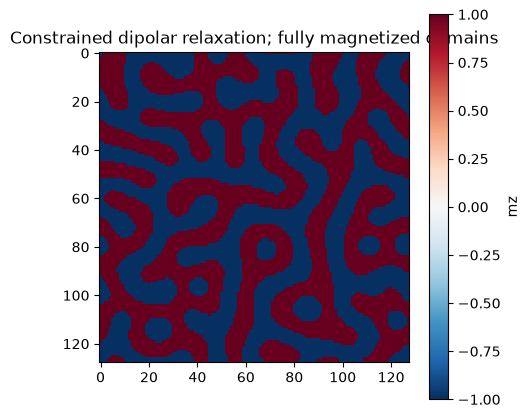

In [2]:
constrained_shape = (128, 128)
constrained_parameters = dict(
    target_magnetization=0.0,  # M/Ms: 0 = half up, half down; +0.6 = 80% up
    characteristic_length=16.0,  # target full repeat/spacing, in pixels
    alignment=0.0,  # try 8 for aligned stripes
    direction=0.0,  # stripe-axis angle in radians
    disorder=0.0, disorder_length=1.0,
    initial_state="random",  # random, stripes, hexagonal
    initial_order=0.0,  # blend ordered seed into random field
    wall_stiffness=2.0, n_steps=400, time_step=0.2,
    length_tolerance=0.15, max_length_iterations=5, seed=7,
)
constrained_mz, constrained_meta = create_constrained_domain_pattern(
    constrained_shape, **constrained_parameters)
print({key: constrained_meta[key] for key in (
    "mean_mz", "up_fraction_measured", "measured_length_px", "length_target_met",
    "converged", "residual", "steps_completed", "nematic_order", "elapsed_seconds")})
assert set(np.unique(constrained_mz)) <= {-1., 1.}
assert all(row["up_pixels"] == constrained_meta["target_up_pixels"] for row in constrained_meta["trace"])
plt.figure(figsize=(5, 5))
plt.imshow(constrained_mz, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
plt.title("Constrained dipolar relaxation; fully magnetized domains")
plt.colorbar(label="mz"); plt.show()


### Measured model examples

The saved comparison includes labyrinths, aligned stripes, minority bubbles,
ordered bubble and stripe preparations, and a pinned labyrinth. It records
achieved size, elapsed time and whether relaxation reached the residual
criterion. A finite-step pattern may remain metastable or still be relaxing.
These examples are not a benchmark against full micromagnetics.


60 measured model trials


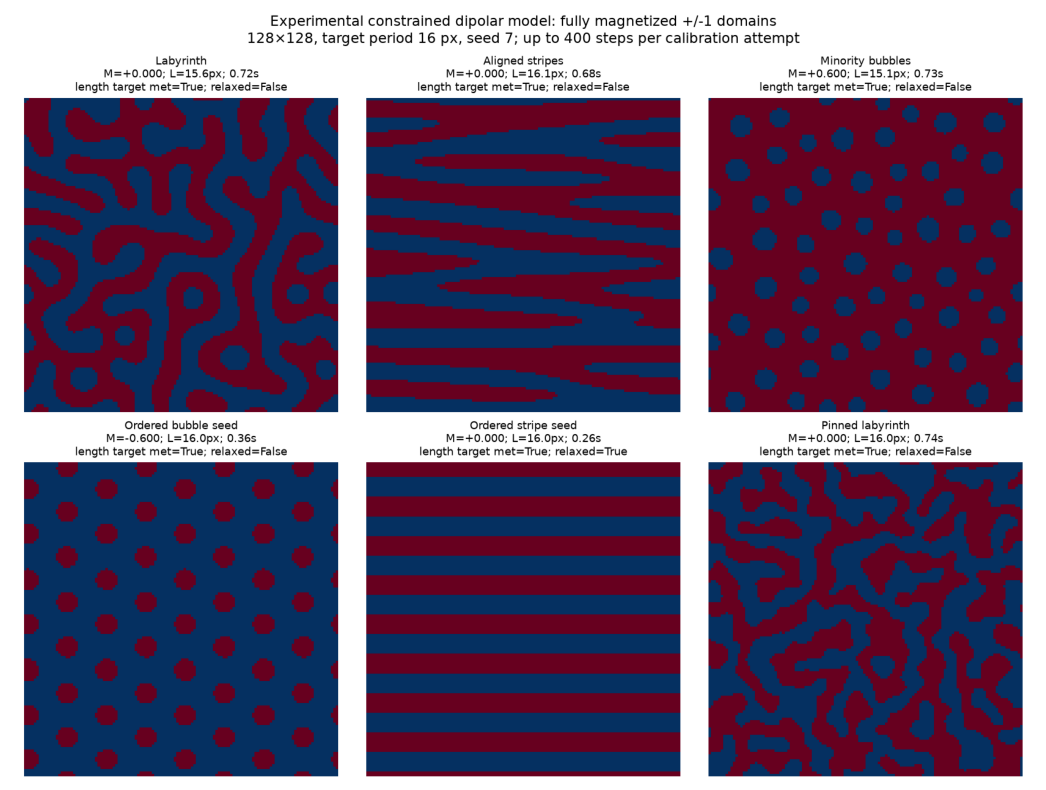

In [3]:
trial_dir = root / "docs/assets/constrained_domains"
if (trial_dir / "measurements.json").exists():
    trial_results = json.loads((trial_dir / "measurements.json").read_text())
    print(f"{len(trial_results['records'])} measured model trials")
    plt.figure(figsize=(14, 10))
    plt.imshow(plt.imread(trial_dir / "morphologies.png"))
    plt.axis("off"); plt.show()
else:
    print("Generate the measured trial with: PYTHONPATH=src python scripts/catalogue_constrained_domains.py")


## Explore the constrained model parameter by parameter

Each gallery changes **one control** from `explorer_base`; all other settings
and the random seed stay fixed. The code above each gallery exposes its sampled
values. Colors always mean +1 (red) and -1 (blue), never relative image contrast.
Titles report achieved M, measured repeat L, stripe order S2, and size/convergence
flags. A different preparation or pinning strength is explicitly set in the few
comparisons where it is needed to make a control meaningful.

For quick exploration the default is **one length-calibration attempt**. Thus L
may differ from the requested characteristic length. Increase
`explorer_base["max_length_iterations"]` to 5 to explore calibrated output sizes.
The numerical controls and seed also have galleries; they are not material
parameters. Generate these figures without any optical simulation.


In [ ]:
# Edit this baseline and rerun whichever galleries you want.
explorer_shape = (128, 128)
explorer_base = dict(constrained_parameters)
explorer_base.update(n_steps=300, max_length_iterations=1, seed=7)
# Classification settings apply to every generated pattern.
# Optional Boolean OH mask on explorer_shape; None selects the whole grid.
explorer_analysis_mask = None
classification_options = dict(min_area=9, max_eccentricity=0.95,
                              min_circularity=0.4, connectivity=2, periodic=False,
                              boundary_context_periodic=True)
explorer_results = {}  # Reused across galleries; includes full controls and metadata.

def explorer_sample(controls):
    import copy
    settings = dict(explorer_base, **controls)
    key = json.dumps({"shape": explorer_shape, "controls": settings, "classification": classification_options,
                      "analysis_mask": None if explorer_analysis_mask is None else np.asarray(explorer_analysis_mask, dtype=bool).tolist()}, sort_keys=True)
    if key not in explorer_results:
        pattern, metadata = create_constrained_domain_pattern(explorer_shape, **settings)
        from scattering_calculator.sample_generator.domain_analysis import classify_magnetic_domains
        classification = classify_magnetic_domains(pattern, analysis_mask=explorer_analysis_mask, **classification_options)
        explorer_results[key] = {"parameters": copy.deepcopy(settings),
                                 "pattern": pattern, "metadata": metadata,
                                 "classification": classification,
                                 "analysis_mask": None if explorer_analysis_mask is None else np.array(explorer_analysis_mask, dtype=bool, copy=True)}
    return explorer_results[key]

def explorer_value(value):
    return f"{value:.3g}" if isinstance(value, (float, np.floating)) else str(value)

def draw_explorer_domain(ax, sample, label):
    metadata = sample["metadata"]
    period = metadata["measured_length_px"]
    order = metadata["nematic_order"]
    period_text = "undefined" if period is None else f"{period:.1f} px"
    order_text = "undefined" if order is None else f"{order:.2f}"
    ax.imshow(sample["pattern"], cmap="RdBu_r", vmin=-1, vmax=1,
              interpolation="nearest", extent=(0, explorer_shape[1], explorer_shape[0], 0))
    classification = sample["classification"]
    state_text = (f"{classification['state']}: B={classification['bubble_count']}, "
                  f"S={classification['stripe_count']}; edge fragments={classification['boundary_fragment_count']}\n"
                  f"(B+/B-={classification['positive_bubble_count']}/{classification['negative_bubble_count']}; "
                  f"S+/S-={classification['positive_stripe_count']}/{classification['negative_stripe_count']})")
    stripe_order = classification["stripe_nematic_order"]
    bubble_order = classification["sixfold_order"]
    symmetry = f"stripe S2={stripe_order:.2f}" if stripe_order is not None else "stripe S2=undefined"
    symmetry += f"; bubble |ψ6|={bubble_order:.2f}" if bubble_order is not None else "; bubble |ψ6|=undefined"
    ax.set_title(f"{label}\nM={metadata['mean_mz']:+.2f}; L={period_text}; S2={order_text}\n"
                 f"{state_text}\n{symmetry}\nsize met={metadata['length_target_met']}; converged={metadata['converged']}", fontsize=8)
    ax.set_axis_off()

def explore_domain_parameter(parameter, values, *, fixed=None):
    """Change one control with a fixed seed; store every generated result."""
    values = list(values)
    if not values:
        raise ValueError("Supply at least one parameter value")
    fixed = dict(fixed or {})
    columns = min(5, len(values))
    rows = (len(values) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3.2*columns, 3.9*rows),
                             squeeze=False, constrained_layout=True)
    samples = []
    for ax, value in zip(axes.ravel(), values):
        controls = dict(fixed)
        controls[parameter] = value
        sample = explorer_sample(controls)
        samples.append(sample)
        draw_explorer_domain(ax, sample, f"{parameter}={explorer_value(value)}")
    for ax in axes.ravel()[len(values):]:
        ax.set_axis_off()
    subtitle = f"; fixed overrides: {fixed}" if fixed else ""
    fig.suptitle(f"Vary {parameter}{subtitle}", fontsize=11)
    plt.show()
    plt.close(fig)
    return samples


### Net magnetization / occupied area

The domain values stay +1/-1; only occupied areas change. At saturation there is no measurable domain repeat.


In [ ]:
magnetization_samples = explore_domain_parameter(
    "target_magnetization", [-1.0, -0.6, 0.0, 0.6, 1.0])


### Characteristic domain spacing

This is a full repeat/spacing, not a bubble diameter or an individual stripe width. Read measured L as well as the requested value.


In [ ]:
length_samples = explore_domain_parameter(
    "characteristic_length", [8.0, 12.0, 16.0, 24.0, 32.0])


### Stripe alignment strength

Direction is held fixed. Alignment is an energetic preference, independent of a stripe seed. S2 measures stripe orientation order.


In [ ]:
alignment_samples = explore_domain_parameter(
    "alignment", [0.0, 0.5, 2.0, 8.0, 24.0])


### Preferred stripe direction

Alignment is fixed at 8 here so direction has an effect. The angle is the stripe axis, from +x towards +y, in radians. Opposite stripe directions are equivalent.


In [ ]:
direction_samples = explore_domain_parameter(
    "direction", [0.0, np.pi/6, np.pi/4, np.pi/3, np.pi/2], fixed={"alignment": 8.0})


### Pinning disorder strength

The quenched field uses the same realization and correlation length. Only its amplitude changes.


In [ ]:
disorder_samples = explore_domain_parameter(
    "disorder", [0.0, 0.1, 0.3, 0.6, 1.0])


### Pinning correlation length

Disorder is fixed at 0.5; otherwise its correlation length would have no effect. Lengths are pixels.


In [ ]:
disorder_length_samples = explore_domain_parameter(
    "disorder_length", [0.0, 0.5, 1.0, 2.0, 4.0], fixed={"disorder": 0.5})


### Initial preparation

Initial order is fixed at 1 for ordered preparations; random preparation remains random. These are starting conditions, not guaranteed final phases.


In [ ]:
preparation_samples = explore_domain_parameter(
    "initial_state", ["random", "stripes", "hexagonal", "worms"],
    fixed={"initial_order": 1., "target_magnetization": 0.9})


### Strength of the ordered seed

A hexagonal seed and M=-0.6 are fixed here. This blends random and ordered starting fields; it is distinct from the alignment energy.


In [ ]:
initial_order_samples = explore_domain_parameter(
    "initial_order", [0.0, 0.25, 0.5, 0.75, 1.0], fixed={"initial_state": "hexagonal", "target_magnetization": -0.6})


### Auxiliary-field wall stiffness

This dimensionless local double-well coefficient affects interface relaxation. It is not yet calibrated to a material exchange or anisotropy constant.


In [ ]:
wall_stiffness_samples = explore_domain_parameter(
    "wall_stiffness", [1.0, 2.0, 4.0, 8.0])


### Different stochastic realizations

All physical controls stay fixed. This shows variation across random initial conditions.


In [ ]:
seed_samples = explore_domain_parameter(
    "seed", [7, 11, 23, 47, 101])


### Relaxation budget

These use the same initialization and time step. More steps change relaxation effort, not the material. Check residual convergence separately from appearance.


In [ ]:
steps_samples = explore_domain_parameter(
    "n_steps", [25, 100, 300, 600, 1200])


### Numerical time step

The step count stays fixed, so total relaxation time also changes. This gallery is exploratory; it is not a matched-time convergence study.


In [ ]:
time_step_samples = explore_domain_parameter(
    "time_step", [0.05, 0.1, 0.2, 0.4])


### Residual stopping tolerance

The tolerance must hold for five consecutive steps. Loose tolerances may stop prematurely; inspect steps completed and residual in the stored metadata.


In [ ]:
stopping_samples = explore_domain_parameter(
    "convergence_tolerance", [1e-2, 1e-3, 1e-4, 1e-5])


### Length-calibration budget

Each additional attempt reruns the same-seed relaxation at an adjusted preferred scale. Compare the size flag and measured L; success is not guaranteed.


In [ ]:
calibration_samples = explore_domain_parameter(
    "max_length_iterations", [1, 2, 3, 5])


### Accepted relative size error

This changes acceptance during calibration, not the material model. Five attempts are allowed for this comparison.


In [ ]:
size_tolerance_samples = explore_domain_parameter(
    "length_tolerance", [0.05, 0.1, 0.15, 0.25], fixed={"max_length_iterations": 5})


## One or two isolated minority worm domains

Strong net magnetization does not require a bubble lattice. Prepare finite
minority worms with `initial_state="worms"`, `initial_order=1` and
`initial_domain_count=1` or `2`. The same dipolar model then relaxes those seeds;
it does **not** enforce their final topology. Domain count can change through
breakup or merging. Both signs below have fully magnetized +/-1 domains.

These examples use zero alignment to keep curved, finite worms rather than
favor stripes that wrap around the periodic box. Length calibration is disabled:
a global spectral repeat is not a useful independent constraint for one isolated
worm. The panels still report measured size and flags. `worm_length` and
`worm_waviness` describe preparation, not frozen final geometry.

At |M|=0.9 the two-worm recipe uses a shorter preferred interaction scale
(16 rather than 24 pixels), consistent with the smaller available minority area.
These are recipes for sparse worms, not a one-control-at-a-time comparison.


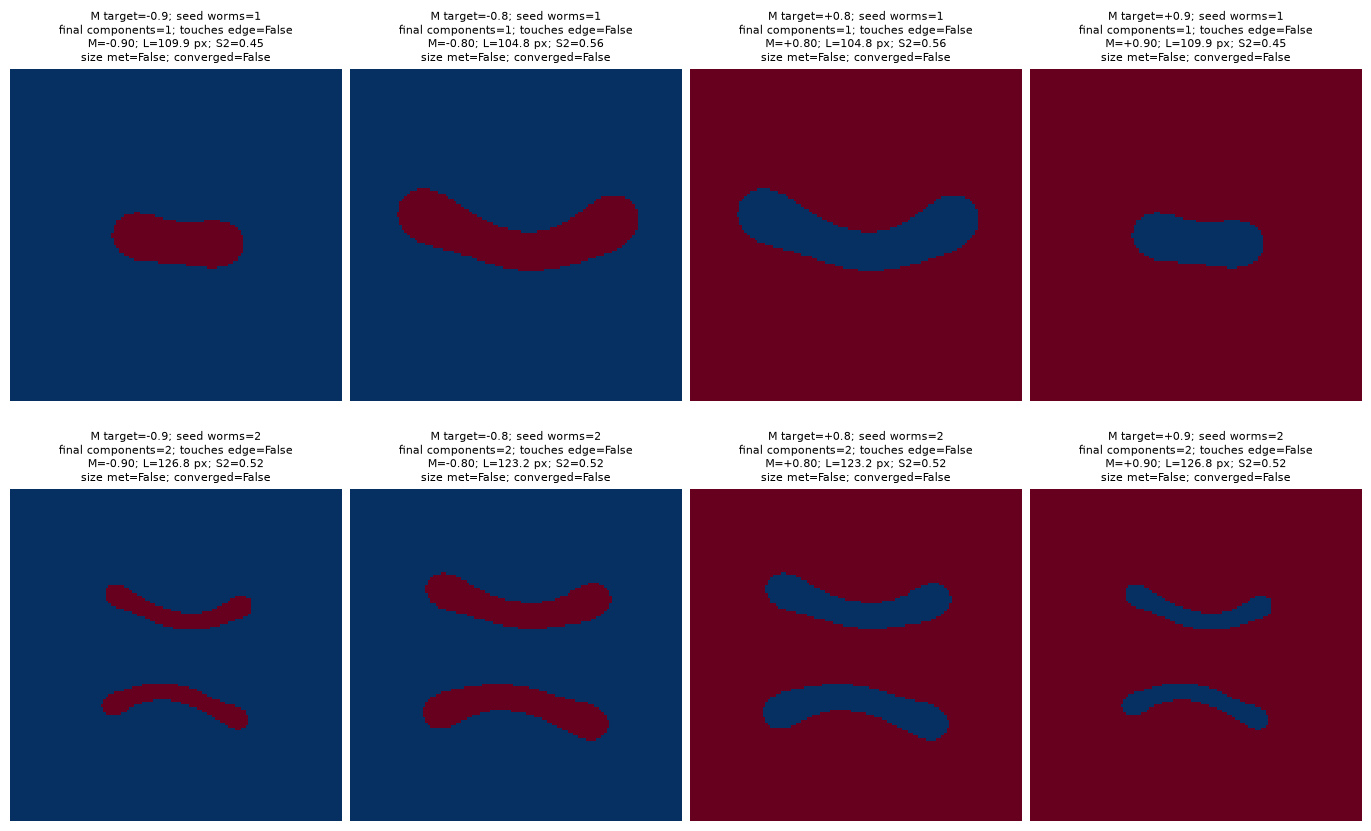

In [22]:
from scipy import ndimage
worm_magnetizations = [-0.9, -0.8, 0.8, 0.9]
worm_counts = [1, 2]
fig, axes = plt.subplots(len(worm_counts), len(worm_magnetizations),
    figsize=(3.4*len(worm_magnetizations), 4.2*len(worm_counts)), squeeze=False, constrained_layout=True)
worm_samples = []
for row, count in enumerate(worm_counts):
    for col, magnetization in enumerate(worm_magnetizations):
        sample = explorer_sample(dict(
            target_magnetization=magnetization, initial_state="worms", initial_order=1.,
            initial_domain_count=count, characteristic_length=32. if count == 1 else (16. if abs(magnetization) > .85 else 24.),
            worm_length=0.6*min(explorer_shape), worm_waviness=0.06*min(explorer_shape),
            alignment=0., disorder=0., n_steps=400, max_length_iterations=1))
        pattern = sample["pattern"]
        minority = pattern < 0 if magnetization >= 0 else pattern > 0
        _, components = ndimage.label(minority, structure=np.ones((3,3)))
        touches_edge = any(np.any(edge) for edge in (minority[0], minority[-1], minority[:,0], minority[:,-1]))
        draw_explorer_domain(axes[row,col], sample,
            f"M target={magnetization:+.1f}; seed worms={count}\n"
            f"final components={components}; touches edge={touches_edge}")
        worm_samples.append(sample)
plt.show()
plt.close(fig)


### Two-parameter exploration

Change the axis names and sampled values below to explore interactions. Each
panel uses the baseline plus its row and column controls. For example, try
`characteristic_length` versus `alignment`, or `disorder` versus
`target_magnetization`. A fixed-override dictionary can set the seed preparation.


In [ ]:
def explore_domain_grid(x_parameter, x_values, y_parameter, y_values, *, fixed=None):
    if x_parameter == y_parameter:
        raise ValueError("Choose different row and column controls")
    x_values, y_values = list(x_values), list(y_values)
    if not x_values or not y_values:
        raise ValueError("Both axes need at least one value")
    fig, axes = plt.subplots(len(y_values), len(x_values),
        figsize=(3.2*len(x_values), 3.8*len(y_values)), squeeze=False, constrained_layout=True)
    samples = []
    for row, y_value in enumerate(y_values):
        for col, x_value in enumerate(x_values):
            controls = dict(fixed or {})
            controls.update({x_parameter: x_value, y_parameter: y_value})
            sample = explorer_sample(controls)
            samples.append(sample)
            draw_explorer_domain(axes[row, col], sample,
                f"{x_parameter}={explorer_value(x_value)}\n{y_parameter}={explorer_value(y_value)}")
    fig.suptitle(f"{y_parameter} versus {x_parameter}", fontsize=12)
    plt.show()
    plt.close(fig)
    return samples

grid_samples = explore_domain_grid(
    "target_magnetization", [-0.6, 0.0, 0.6],
    "alignment", [0.0, 2.0, 8.0],
)


### Inspect and save state classifications

Every gallery shows the total bubble count B and stripe count S, summed over
both positive and negative domains. Separate `positive_*`, `negative_*`,
`majority_*` and `minority_*` counts are also retained and exported.
Classification is measured **after** generation, independently of the requested
preparation. Set `explorer_analysis_mask` to the Boolean OH mask on the full
simulation grid to restrict which domains are counted; `None` uses the whole grid. Edit `classification_options` in the explorer setup cell and rerun.

- B>0, S=1: bubble state; B=0, S>1: stripe state.
- B>0, S>1: mixed state; B=0, S=1: saturated state.
- If the OH excludes the background, B>0, S=0 is also called a bubble state.
  B=S=0 is unresolved at the size cutoff. Check `noise_count` for discarded
  islands; the state label reflects resolved counts, not exact uniformity.
- Compact circular or elliptical components of either polarity are bubbles (default maximum
  axis ratio approximately 3.2:1 and minimum circularity 0.4); all other resolved
  components are stripe-like. The connected majority background is counted as a domain too. Polarity is
  determined over the full simulation grid; at equal area fractions positive
  is called minority for bookkeeping. A completely uniform simulation is saturated with B=0, S=1. A connected labyrinth is one
  component; this does not count branches or individual turns.
- Counting both polarities means a lattice of minority bubbles in one connected
  majority background can have B=N, S=1 and therefore a bubble state. The
  per-polarity counts retain the bubble-only character of the minority phase.
- With an OH `analysis_mask`, shapes are measured on the **full simulation
  pattern** and only components intersecting the OH are counted, once each.
  A bubble clipped by the OH remains a bubble; domains entirely outside are
  excluded. Even a small visible sliver counts if the full domain passes the
  minimum area (default 9 pixels). `visible_area` records its OH overlap.
  The explorer uses `periodic=False`: opposite simulation edges are not joined,
  and whole bubble counts exclude edge-clipped bubbles. With
  `boundary_context_periodic=True`, the periodic solver's opposite-edge pixels
  identify confirmed clipped-bubble fragments; these are saved separately as
  `boundary_fragment_count` and excluded from both B and S. They do not cause
  a bubble-on-background pattern to be labelled mixed. Actual winding stripes
  and non-bubble domains still contribute to S. This counts
  bubbles using the displayed open field, even though the generator evolves on a
  periodic grid. Set `periodic=True` to join and unwrap opposite edges instead.
  OH clipping alone never changes the full-domain shape classification. Counts depend on resolution,
  OH size, connectivity and minimum full-domain area.
- `stripe_nematic_order` ranges from 0 to 1 and compares component major axes,
  weighted by area and elongation. Parallel stripes approach 1; a single elongated
  component also gives 1, so this alone does not establish periodic order.
- `local_sixfold_order` averages the magnitude of six-neighbor bond order around
  bubble centers. `sixfold_order` measures their shared global orientation.
  Hexagonal arrangements approach 1; differently oriented grains can retain high
  local order and lower global order. At least seven resolved bubbles are needed.
  These are orientational measures, not proofs of translational crystal symmetry.
  Undefined order is `None` in Python and NaN in HDF5.

Set `SAVE_EXPLORATION=True` below to save the patterns, controls, metadata and
classification to `states.h5` in a new output directory. Each `states/0000/`
contains `magnetization`, `parameters_json`, `metadata_json`, and a
`classification/` group with named scalar datasets, including thresholds.
The NPY and JSON export is retained as well.


In [ ]:
print(f"{len(explorer_results)} unique generated configurations cached")
# Example: inspect the first configuration and its measurements.
if explorer_results:
    first_sample = next(iter(explorer_results.values()))
    print(first_sample["parameters"])
    print(first_sample["metadata"]["measurements"])
    c = first_sample["classification"]
    print({key: c[key] for key in ("state", "bubble_count", "stripe_count", "boundary_fragment_count", "noise_count",
                                  "stripe_nematic_order", "local_sixfold_order", "sixfold_order")})

SAVE_EXPLORATION = False
if SAVE_EXPLORATION:
    from datetime import datetime
    from uuid import uuid4
    output = root / "outputs/domain_exploration" / (datetime.now().strftime("%Y%m%d_%H%M%S_") + uuid4().hex[:8])
    output.mkdir(parents=True, exist_ok=False)
    import h5py
    from scattering_calculator.sample_generator.domain_analysis import write_domain_classification
    with h5py.File(output / "states.h5", "x") as h5:
        for index, sample in enumerate(explorer_results.values()):
            state_group = h5.create_group(f"states/{index:04d}")
            state_group.create_dataset("magnetization", data=sample["pattern"], compression="gzip")
            state_group.create_dataset("parameters_json", data=json.dumps(sample["parameters"], allow_nan=False))
            state_group.create_dataset("metadata_json", data=json.dumps(sample["metadata"], allow_nan=False))
            if sample["analysis_mask"] is not None:
                state_group.create_dataset("analysis_mask", data=sample["analysis_mask"], compression="gzip")
            c = sample["classification"]
            write_domain_classification(state_group.create_group("classification"), sample["pattern"],
                analysis_mask=sample["analysis_mask"], min_area=c["classification_min_area_px"], threshold=c["classification_threshold"],
                max_eccentricity=c["bubble_max_eccentricity"],
                min_circularity=c["bubble_min_circularity"], connectivity=c["classification_connectivity"], periodic=c["periodic"],
                boundary_context_periodic=c["boundary_context_periodic"])
    records = []
    for index, sample in enumerate(explorer_results.values()):
        np.save(output / f"domain_{index:04d}.npy", sample["pattern"])
        records.append({"pattern_file": f"domain_{index:04d}.npy",
                        "parameters": sample["parameters"], "metadata": sample["metadata"]})
    (output / "measurements.json").write_text(json.dumps(records, indent=2, allow_nan=False))
    print(f"Saved {len(records)} configurations to {output}")


## Editable controls

`target_mean` constrains the evolving continuous field; `up_fraction` constrains
the final sign area fraction. Domains are +1 and -1; the fraction changes
occupied area, never their magnetization strength. They are different quantities. Use `None` for
`up_fraction` to observe the occupancy selected by evolution. Ordered positive
bubble lattices can be seeded with `lattice_order=1, up_fraction=0.15`.
Lengths below are pixels; `MagneticPatternConfig` accepts metres.


In [ ]:
parameters = dict(period=16., up_fraction=.3, target_mean=None,
                  lattice_order=0., lattice_angle=0., k0=.7, eps=.8,
                  quadratic_coefficient=0., field_bias=0., n_steps=80,
                  noise_amp=0., sigma=.7, domain_conversion="hard", seed=11, use_gpu=False)
shape = (128, 128)
mz, metadata = create_domain_pattern(shape, **parameters)
metrics = measure_domain_pattern(mz)
print(metrics)
plt.figure(figsize=(5,5))
plt.imshow(mz, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
plt.colorbar(label="mz"); plt.title("Scalar magnetic domains"); plt.show()


## Same model, different shapes and fractions

The first row uses random initial conditions; the second uses hexagonal seeds.
Quantile calibration fixes occupancy, while the model and seed determine shape.


In [ ]:
fractions = [.15, .3, .5, .7, .85]
orders = [0., 1.]
fig, axes = plt.subplots(len(orders), len(fractions), figsize=(14,6), squeeze=False, constrained_layout=True)
for row, order in enumerate(orders):
    for col, fraction in enumerate(fractions):
        controls = dict(parameters, up_fraction=fraction, lattice_order=order)
        pattern, meta = create_domain_pattern(shape, **controls)
        axes[row,col].imshow(pattern, cmap="RdBu_r", vmin=-1, vmax=1)
        axes[row,col].set_title(f"order={order:g}, f+={meta['up_fraction_measured']:.2f}")
        axes[row,col].set_axis_off()
plt.show()


## Natural occupancy from evolution

No quantile correction is applied in this comparison. The printed mean `mz`
is the area-weighted mean of fully magnetized domains: `mean_mz = 2*f_up - 1`.


In [ ]:
means = [-.8, -.4, 0., .4, .8]
fig, axes = plt.subplots(1, len(means), figsize=(14,3), squeeze=False, constrained_layout=True)
for ax, mean in zip(axes.ravel(), means):
    pattern, meta = create_domain_pattern(shape, **dict(parameters, target_mean=mean, up_fraction=None))
    ax.imshow(pattern, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"mean control={mean:g}\nf+={meta['up_fraction_measured']:.2f}, <mz>={meta['mean_mz']:.2f}")
    ax.set_axis_off()
plt.show()


## Labyrinthine stripes from Tutorial 03

The earlier examples emphasized occupancy and ordered bubbles. Tutorial 03 also
varies the native spectral wavelength and uses the legacy explicit evolution.
Here the same general function uses `rescale_mode="native"`,
`stable_evolution=False`, `target_mean=0`, and no occupancy correction.
The period follows `k0`; the `period` argument is not applied in native mode.
Domains remain +1/-1. Lower `k0` produces broader, smoother labyrinthine stripes.


In [ ]:
stripe_k0 = [.2, .7]
stripe_eps = [.1, .6, 1.2]
fig, axes = plt.subplots(len(stripe_k0), len(stripe_eps), figsize=(12,8), squeeze=False, constrained_layout=True)
for row, k0 in enumerate(stripe_k0):
    for col, eps in enumerate(stripe_eps):
        pattern, meta = create_domain_pattern(
            shape, period=16, k0=k0, eps=eps, target_mean=0., up_fraction=None,
            lattice_order=0., stable_evolution=False, rescale_mode="native",
            sigma=None, domain_conversion="hard", max_hole_area=9,
            n_steps=80, noise_amp=0., seed=7, use_gpu=False)
        metrics = measure_domain_pattern(pattern)
        axes[row,col].imshow(pattern, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
        axes[row,col].set_title(f"k0={k0:g}, eps={eps:g}; f+={metrics['up_fraction']:.2f}")
        axes[row,col].set_axis_off()
plt.show()


## Inspect the measured catalogue

Every record includes parameters and observations; shape labels are empirical.
Border-clipped circles can be classified as stripe-like. Sixfold order is a
center-neighbor statistic, not a skyrmion topological invariant.


In [ ]:
catalogue = json.loads((root / "docs/assets/domain_catalogue/catalogue.json").read_text())
records = catalogue["records"]
print(f"{len(records)} measured samples; seeds={catalogue['seeds']}")
for panel in dict.fromkeys(record["panel"] for record in records):
    plt.figure(figsize=(14,9))
    plt.imshow(plt.imread(root / "docs/assets/domain_catalogue" / f"{panel}.png"))
    plt.axis("off"); plt.show()
